**Sommaire**<a id='toc0_'></a>    
  - [Gestion de l'environnement de travail](#toc1_1_1_)    
  - [Extraction des données](#toc1_2_)    
    - [Departments](#toc1_2_1_)    
  - [Variable selection](#toc1_3_)    
    - [Concatenation of both datasets.](#toc1_3_1_)    
  - [Cleaning data (missing values and outliers)](#toc1_4_)    
    - [Années](#toc1_4_1_)    
    - [Cout 5 usages](#toc1_4_2_)    
    - [type_energie_principale_chauffage](#toc1_4_3_)    
    - [surface_habitable_logement](#toc1_4_4_)    
    - [hauteur_sous_plafond](#toc1_4_5_)    
    - [nombre_niveau_logement](#toc1_4_6_)    
    - [type_batiment](#toc1_4_7_)    
    - [code_insee](#toc1_4_8_)    
    - [department](#toc1_4_9_)    
  - [Checking the final data frame after cleaning values.](#toc1_5_)    
  - [Extracting lat and long from the "_geopoint" column.](#toc1_6_)    
  - [Mapping climate area](#toc1_7_)    
  - [Adding altitude](#toc1_8_)    
    - [Preparing the data for mapping altitude values.](#toc1_8_1_)    
    - [Merging](#toc1_8_2_)    
  - [Final check and writing .csv](#toc1_8_3_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

### <a id='toc1_1_1_'></a>[Gestion de l'environnement de travail](#toc0_)

In [ ]:
# Variable globale pour exécuter ou non les blocs de code d’extraction.
EXTRACTION = False

In [17]:
# Import des packages
import datetime as dt

import matplotlib.pyplot as plt

# import des librairies.
import pandas as pd

from helpers.api_requesters import Ademe_API_requester

## <a id='toc1_2_'></a>[Extraction des données](#toc0_)

In [18]:
# Initialisation de l'API requester
ademe = Ademe_API_requester()

### <a id='toc1_2_1_'></a>[Departments](#toc0_)

In [19]:
if EXTRACTION:
    # Fetching number of datapoints per department.
    departments_old = pd.DataFrame(ademe.get_all_departments_count(neuf=False)).drop(
        columns=["results"]
    )
    departments_new = pd.DataFrame(ademe.get_all_departments_count(neuf=True)).drop(
        columns=["results"]
    )

    # Renaming and reorganizing columns
    departments_old = departments_old.rename(columns={"value": "department"})[
        ["department", "total"]
    ]
    departments_new = departments_new.rename(columns={"value": "department"})[
        ["department", "total"]
    ]

    # Get rid of departments from Corse and Outer-seas.
    departments_old = departments_old[~departments_old["department"].isin(["2A", "2B"])]
    departments_old = departments_old[
        ~departments_old["department"].apply(lambda x: len(x) > 2)
    ]
    departments_new = departments_new[~departments_new["department"].isin(["2A", "2B"])]
    departments_new = departments_new[
        ~departments_new["department"].apply(lambda x: len(x) > 2)
    ]

In [20]:
if EXTRACTION:
    # Verify that both dataframes contain the same departments.
    all(departments_old["department"].isin(departments_new["department"]))

In [21]:
if EXTRACTION:
    # Get a list of all departments.
    departments_list = departments_old["department"].tolist()

    # Nombre de département
    len(departments_list)

Décommentez la cellule suivante pour l’extraction.

In [22]:
if EXTRACTION:
    data_old = []
    data_new = []

    # Request old data for all departments and write the result to a csv file.
    for i, department in enumerate(departments_list):
        print(
            f"Requesting data for department {department} ({i + 1}/{len(departments_list)})"
        )

        print("Old housing:")
        result = ademe.custom_lines_request(
            neuf=False, qs=f"code_departement_ban:{department}", limit=5000
        )

        # Add the data to the list
        data_old.extend(result)

        # Same on
        print("New housing:")
        result_new = ademe.custom_lines_request(
            neuf=True, qs=f"code_departement_ban:{department}", limit=5000
        )

        # Add the data to the list
        data_new.extend(result_new)

    # Convert the data to a dataframe
    df_old = pd.DataFrame(data_old)
    df_new = pd.DataFrame(data_new)

    # Write the dataframe to a csv file.
    df_old.to_csv("data/ademe_data_old.csv", index=False)
    df_new.to_csv("data/ademe_data_new.csv", index=False)

Requesting data for department 75 (1/94)
Old housing:
New housing:
Requesting data for department 59 (2/94)
Old housing:
New housing:
Requesting data for department 69 (3/94)
Old housing:
New housing:
Requesting data for department 92 (4/94)
Old housing:
New housing:
Requesting data for department 13 (5/94)
Old housing:
New housing:
Requesting data for department 93 (6/94)
Old housing:
New housing:
Requesting data for department 94 (7/94)
Old housing:
New housing:
Requesting data for department 33 (8/94)
Old housing:
New housing:
Requesting data for department 44 (9/94)
Old housing:
New housing:
Requesting data for department 31 (10/94)
Old housing:
New housing:
Requesting data for department 76 (11/94)
Old housing:
New housing:
Requesting data for department 78 (12/94)
Old housing:
New housing:
Requesting data for department 62 (13/94)
Old housing:
New housing:
Requesting data for department 06 (14/94)
Old housing:
New housing:
Requesting data for department 91 (15/94)
Old housing:
Ne

_get_json a échoué (("Connection broken: ConnectionResetError(10054, 'Une connexion existante a dû être fermée par l’hôte distant', None, 10054, None)", ConnectionResetError(10054, 'Une connexion existante a dû être fermée par l’hôte distant', None, 10054, None))). Nouvelle tentative dans 1.0 s.


New housing:
Requesting data for department 67 (22/94)
Old housing:
New housing:
Requesting data for department 35 (23/94)
Old housing:
New housing:
Requesting data for department 74 (24/94)
Old housing:
New housing:
Requesting data for department 51 (25/94)
Old housing:
New housing:
Requesting data for department 49 (26/94)
Old housing:
New housing:
Requesting data for department 14 (27/94)
Old housing:
New housing:
Requesting data for department 54 (28/94)
Old housing:
New housing:
Requesting data for department 29 (29/94)
Old housing:
New housing:
Requesting data for department 42 (30/94)
Old housing:
New housing:
Requesting data for department 37 (31/94)
Old housing:


_get_json a échoué (("Connection broken: ConnectionResetError(10054, 'Une connexion existante a dû être fermée par l’hôte distant', None, 10054, None)", ConnectionResetError(10054, 'Une connexion existante a dû être fermée par l’hôte distant', None, 10054, None))). Nouvelle tentative dans 1.0 s.


New housing:
Requesting data for department 56 (32/94)
Old housing:
New housing:
Requesting data for department 30 (33/94)
Old housing:
New housing:
Requesting data for department 64 (34/94)
Old housing:
New housing:
Requesting data for department 17 (35/94)
Old housing:
New housing:
Requesting data for department 60 (36/94)
Old housing:
New housing:
Requesting data for department 45 (37/94)
Old housing:
New housing:
Requesting data for department 68 (38/94)
Old housing:
New housing:
Requesting data for department 63 (39/94)
Old housing:
New housing:
Requesting data for department 21 (40/94)
Old housing:
New housing:
Requesting data for department 85 (41/94)
Old housing:
New housing:
Requesting data for department 73 (42/94)
Old housing:
New housing:
Requesting data for department 01 (43/94)
Old housing:
New housing:
Requesting data for department 84 (44/94)
Old housing:
New housing:
Requesting data for department 50 (45/94)
Old housing:
New housing:
Requesting data for department 27 (

## <a id='toc1_3_'></a>[Selection de variables](#toc0_)

**Objectif**: générer un échantillon d’entraînement et de test, représentatif de toutes les étiquettes DPE, réparties dans toutes les régions.

### <a id='toc1_3_1_'></a>[Concatenation of both datasets.](#toc0_)

In [ ]:
# Lire les anciens fichiers.
df_old = pd.read_csv("data/ademe_data_old.csv", low_memory=False)

In [101]:
df_old.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 470000 entries, 0 to 469999
Columns: 228 entries, configuration_installation_chauffage_n1 to facteur_couverture_solaire_saisi_installation_chauffage_n2
dtypes: float64(122), int64(8), object(98)
memory usage: 817.6+ MB


In [ ]:
# Lire les nouveaux fichiers
df_new = pd.read_csv("data/ademe_data_new.csv", low_memory=False)

In [103]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364959 entries, 0 to 364958
Columns: 196 entries, numero_voie_ban to conso_refroidissement_annuel
dtypes: float64(104), int64(8), object(84)
memory usage: 545.7+ MB


In [ ]:
# Ajouter une année de construction pour les nouveaux logements.
df_new["annee_construction"] = dt.datetime.now().year

In [ ]:
# Générer le dataframe contenant à la fois les anciens et les nouveaux logements.
df_total = pd.concat([df_old, df_new]).reset_index(drop=True)

In [106]:
# Vérification des index dupliqués.
df_total.index.duplicated().any()

np.False_

In [ ]:
# Nombre de logements dans le dataframe total.
len(df_total)

834959

Text(0.5, 1.0, 'Distribution of DPE labels in the dataset')

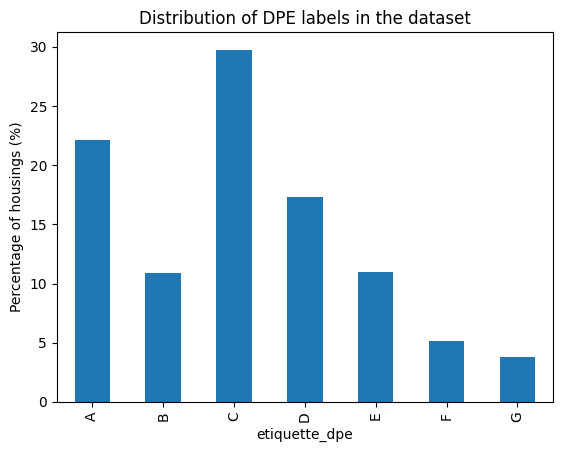

In [ ]:
# Comptage par label DPE
(df_total["etiquette_dpe"].value_counts(normalize=True).sort_index() * 100).plot.bar()
plt.ylabel("Percentage of housings (%)")
plt.title("Distribution of DPE labels in the dataset")

In [109]:
# Répartition des départements.
df_total["code_departement_ban"].value_counts(normalize=True).sort_index().min()

np.float64(0.006188327810108041)

In [110]:
df_total["code_departement_ban"].value_counts(normalize=True).sort_index().max()

np.float64(0.011976635978533077)

-> Les départements sont assez uniformément répartis (un facteur d’environ ×2 entre le minimum et le maximum).

In [ ]:
# Exporter la liste des colonnes.
df_total.columns.tolist()

['configuration_installation_chauffage_n1',
 'conso_chauffage_installation_chauffage_n1',
 'type_generateur_n1_ecs_n1',
 'numero_voie_ban',
 'score_ban',
 'surface_habitable_immeuble',
 'conso_auxiliaires_ep',
 'deperditions_murs',
 'cout_eclairage',
 'conso_auxiliaires_ef',
 'statut_geocodage',
 'ventilation_posterieure_2012',
 'cout_chauffage',
 'conso_5_usages_par_m2_ep',
 'date_etablissement_dpe',
 'conso_ecs_ef_energie_n1',
 'conso_ecs_ef_energie_n2',
 'emission_ges_chauffage',
 'description_installation_chauffage_n1',
 'conso_5_usages_par_m2_ef',
 'cout_ecs_energie_n2',
 'conso_chauffage_ef_energie_n1',
 'conso_chauffage_ef_energie_n2',
 'qualite_isolation_menuiseries',
 'cout_total_5_usages_energie_n2',
 'date_reception_dpe',
 'cout_total_5_usages_energie_n1',
 'cout_ecs_energie_n1',
 'qualite_isolation_plancher_bas',
 'modele_dpe',
 'qualite_isolation_enveloppe',
 'conso_chauffage_generateur_n1_installation_n1',
 'type_energie_n1',
 'emission_ges_eclairage',
 'type_energie_n2',

In [ ]:
# Liste des caractéristiques pertinentes pour le modèle.
# Ne conserver que les caractéristiques avec des valeurs manquantes < 10% et pertinentes pour le modèle.
# EP = énergie primaire
# EF = énergie finale
# ecs = eau chaude sanitaire
#
features = [
    # ----------------------- Classic costs
    "cout_total_5_usages",  # --> OK
    "type_energie_principale_chauffage",  # --> OK
    # "type_energie_principale_ecs",   # ---> Trop de valeurs "autres" (65%)
    # "cout_chauffage",
    # "cout_eclairage",
    # "cout_refroidissement",
    # "cout_auxiliaires",
    # "cout_ecs",
    # "qualite_isolation_menuiseries",
    # "qualite_isolation_plancher_bas",
    # "qualite_isolation_enveloppe",  # --> ok
    # "qualite_isolation_murs",
    # "ubat_w_par_m2_k",
    # # ----------------------- ep costs
    # "conso_5_usages_ep",
    # "conso_5_usages_par_m2_ep",
    # "conso_chauffage_ep",
    # "conso_eclairage_ep",
    # "conso_auxiliaires_ep",
    # "conso_ecs_ep",
    # # ----------------------- ef costs
    # "conso_5_usages_ef",
    # "conso_5_usages_par_m2_ef",
    # "conso_chauffage_ef",
    # "conso_eclairage_ef",
    # "conso_auxiliaires_ef",
    # "conso_ecs_ef",
    # "conso_refroidissement_ef",
    # # ----------------------- n-1 costs (year -1) To be ignored ? Mean ?
    # "cout_total_5_usages_energie_n1",
    # "cout_chauffage_energie_n1",
    # "cout_ecs_energie_n1",
    # "conso_5_usages_ef_energie_n1",
    # "conso_ecs_ef_energie_n1",
    # "conso_chauffage_ef_energie_n1",
    # "type_energie_n1",
    # ----------------------- Building characteristics
    "surface_habitable_logement",  # ---> Ok
    # "hauteur_sous_plafond",  # -----> Ok
    "nombre_niveau_logement",  # ----> Ok drop na
    "type_batiment",  # ----> Ok
    "annee_construction",  # -> Nan éliminés
    # ----------------------- Location features
    "code_insee_ban",
    # "code_region_ban",
    "code_departement_ban",  # ----> Ok, not usefull.
    # ----------------------- Target variable
    "etiquette_dpe",
    # ----------------------- Other needed variables
    "nom_commune_ban",
    "code_postal_ban",
]

In [ ]:
# Nombre de features sélectionnées.
len(features)

11

In [ ]:
# Filtrer le dataframe pour ne garder que les features souhaitées.
df = df_total[features]

En étudiant les données, voici les variables contenant plus de 1 % de valeurs manquantes ::
- qualite_isolation_plancher_bas (5%)
- nombre_niveau_logement (6%)
- année construction (9%)


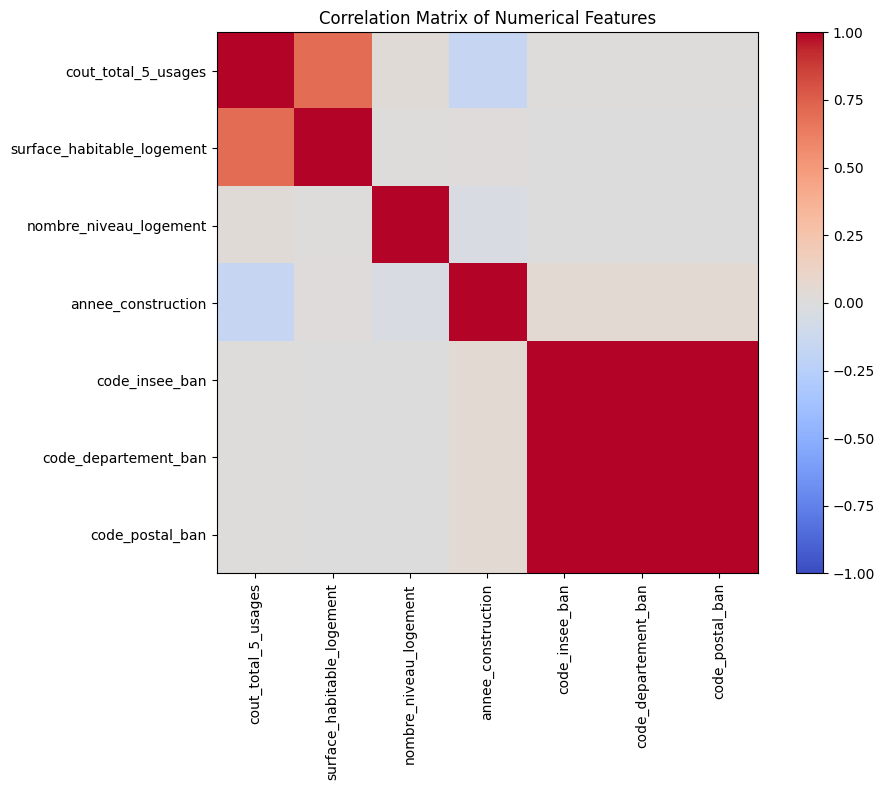

In [115]:
# Calculer la corrélation entre les colonnes numériques
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()
labels = correlation_matrix.columns

# Afficher la matrice
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

fig.colorbar(image, ax=ax)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_title("Correlation Matrix of Numerical Features")

fig.tight_layout()
plt.show()

## <a id='toc1_4_'></a>[Nettoyage des données (valeurs manquantes et valeurs aberrantes))](#toc0_)

### <a id='toc1_4_1_'></a>[Années](#toc0_)

Eliminer les valeurs manquantes, transformer la variable année en "age" pour faciliter le calcul du modèle.

In [42]:
df = df.dropna(subset=["annee_construction"])

<Axes: xlabel='etiquette_dpe'>

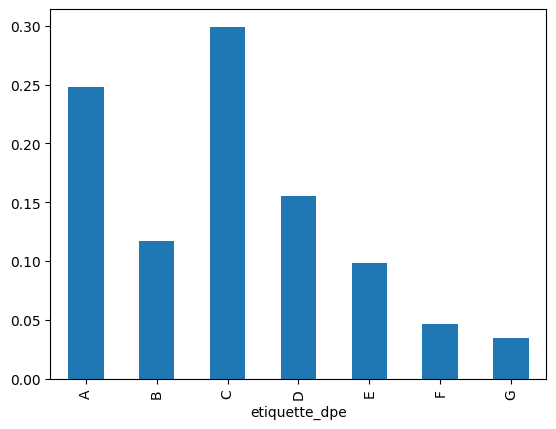

In [43]:
# Verification de la distribution.
df["etiquette_dpe"].value_counts(normalize=True).sort_index().plot(kind="bar")

In [ ]:
# Remplacer par l'âge du bâtiment.
current_year = dt.datetime.now().year
df.loc[:, "age_batiment"] = current_year - df.loc[:, "annee_construction"]
df.drop(columns=["annee_construction"], inplace=True)

In [ ]:
# Supprimer toutes les valeurs négatives.
df = df[df["age_batiment"] >= 0]

<Axes: ylabel='Frequency'>

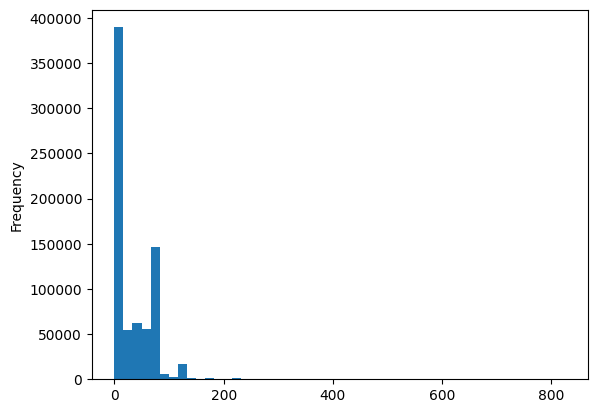

In [ ]:
# checker les valeurs.
df["age_batiment"].plot(kind="hist", bins=50)

### <a id='toc1_4_2_'></a>[Cout 5 usages](#toc0_)

In [47]:
# Elimlination de 125 points de données.
df = df.dropna(subset=["cout_total_5_usages"])

In [48]:
# Suppression des lignes aberrantes (méthode de l'inter-quartile).
Q1 = df["cout_total_5_usages"].quantile(0.25)
Q3 = df["cout_total_5_usages"].quantile(0.75)
IQR = Q3 - Q1

# Filtering the dataframe
df = df[
    (df["cout_total_5_usages"] >= Q1 - 1.5 * IQR)
    & (df["cout_total_5_usages"] <= Q3 + 1.5 * IQR)
]

<Axes: ylabel='Frequency'>

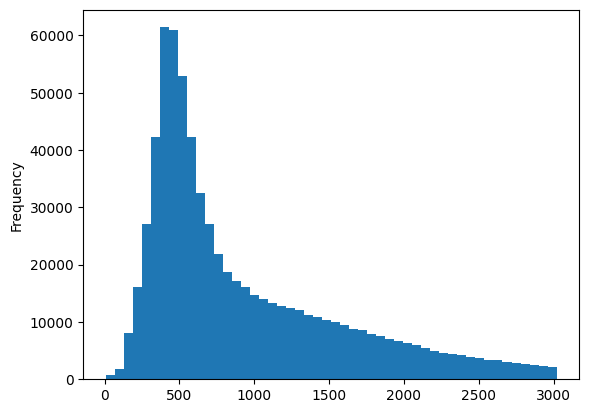

In [ ]:
# checker les valeurs.
df["cout_total_5_usages"].plot(kind="hist", bins=50)

### <a id='toc1_4_3_'></a>[type_energie_principale_chauffage](#toc0_)

In [50]:
# Pas de valeurs nulles.
df["type_energie_principale_chauffage"].isna().sum()

np.int64(0)

In [51]:
# Distribution.
chauffage_distribution = (
    df["type_energie_principale_chauffage"].value_counts(normalize=True) * 100
)

chauffage_distribution

type_energie_principale_chauffage
Électricité                                                     63.044145
Gaz naturel                                                     25.632081
Réseau de Chauffage urbain                                       5.429225
Fioul domestique                                                 1.597095
Bois – Granulés (pellets) ou briquettes                          1.571340
Bois – Bûches                                                    1.500297
Non affecté                                                      0.518716
GPL                                                              0.399780
Propane                                                          0.110399
Électricité d'origine renouvelable utilisée dans le bâtiment     0.109097
Bois – Plaquettes forestières                                    0.067136
Bois – Plaquettes d’industrie                                    0.011141
Charbon                                                          0.006511
Buta

In [ ]:
threshold = 6

# Obtenir la list de toutes les modalités n'atteignant pas le seuil.
rare_modalities = chauffage_distribution[
    chauffage_distribution < threshold
].index.tolist()

# Remplacer les modalités rares par "Autre" dans le dataframe.
df.loc[:, "type_energie_principale_chauffage"] = df[
    "type_energie_principale_chauffage"
].replace(rare_modalities, "Autre")

In [ ]:
# Checker la distribution.
df["type_energie_principale_chauffage"].value_counts(normalize=True) * 100

type_energie_principale_chauffage
Électricité    63.044145
Gaz naturel    25.632081
Autre          11.323774
Name: proportion, dtype: float64

### <a id='toc1_4_4_'></a>[surface_habitable_logement](#toc0_)

In [ ]:
# Vérifier les valeurs manquantes.
df["surface_habitable_logement"].isna().sum()

np.int64(4316)

In [ ]:
# Utiliser la méthode interquartile pour éliminer les valeurs aberrantes (et les valeurs manquantes).
Q1 = df["surface_habitable_logement"].quantile(0.25)
Q3 = df["surface_habitable_logement"].quantile(0.75)
IQR = Q3 - Q1

# Filtering the dataframe
df = df[
    (df["surface_habitable_logement"] >= Q1 - 1.5 * IQR)
    & (df["surface_habitable_logement"] <= Q3 + 1.5 * IQR)
]

In [ ]:
# Vérifier les valeurs manquantes.
df["surface_habitable_logement"].isna().sum()

np.int64(0)

### <a id='toc1_4_6_'></a>[nombre_niveau_logement](#toc0_)

In [ ]:
# Supprimer les valeurs manquantes.
df.loc[:, "nombre_niveau_logement"].dropna(inplace=True)

<Axes: ylabel='Frequency'>

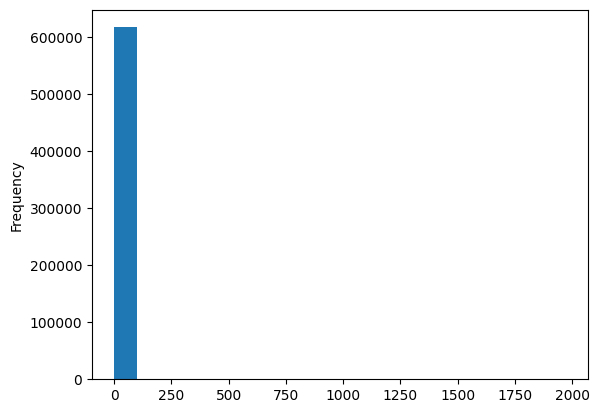

In [ ]:
# Checker les distributions.
df["nombre_niveau_logement"].plot(kind="hist", bins=20)

In [ ]:
# Vérifier les outliers.
df = df[(df["nombre_niveau_logement"] >= 1) & (df["nombre_niveau_logement"] <= 10)]

<Axes: ylabel='Frequency'>

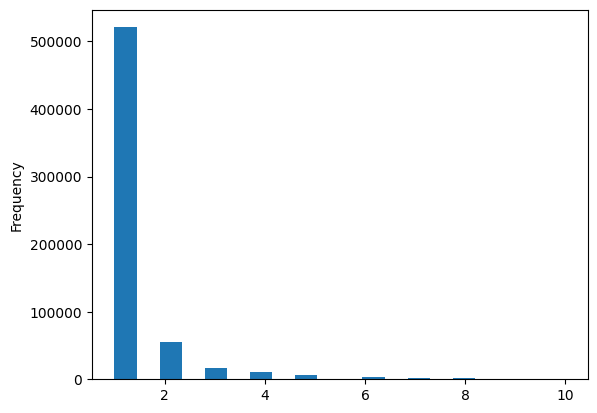

In [ ]:
# checker la distribution des niveaux.
df["nombre_niveau_logement"].plot(kind="hist", bins=20)

### <a id='toc1_4_7_'></a>[type_batiment](#toc0_)

In [ ]:
# checker les valeurs manquantes.
df["type_batiment"].isna().sum()

np.int64(0)

In [ ]:
# checker la distribution.
df["type_batiment"].value_counts(normalize=True) * 100

type_batiment
appartement    53.55722
maison         46.35610
immeuble        0.08668
Name: proportion, dtype: float64

### <a id='toc1_4_8_'></a>[code_insee](#toc0_)

In [ ]:
# Changer le type du code_insee en string.
df["code_insee_ban"] = df["code_insee_ban"].astype(str)

# Ajouter un 0 au début du code insee si celui-ci est trop court.
df["code_insee_ban"] = df["code_insee_ban"].apply(lambda x: x.zfill(5))

### <a id='toc1_4_9_'></a>[department](#toc0_)

In [ ]:
# Ajouter un 0 au début des codes de département qui sont trop courts.
df["code_departement_ban"] = df["code_departement_ban"].astype(str)
df["code_departement_ban"] = df["code_departement_ban"].apply(lambda x: x.zfill(2))

In [ ]:
# verifier la longueur des codes de département.
df["code_departement_ban"].str.len().value_counts()

code_departement_ban
2    616057
Name: count, dtype: int64

## <a id='toc1_5_'></a>[Vérification du data frame final après le nettoyage des valeurs.](#toc0_)

In [ ]:
# Nombre d'observations.
len(df)

616057

<Axes: xlabel='etiquette_dpe'>

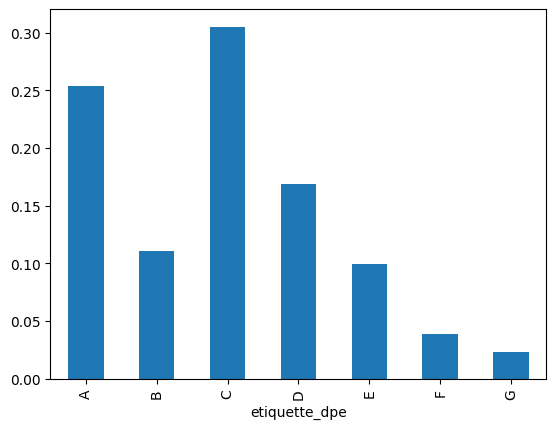

In [ ]:
# Répartition DPE.
df["etiquette_dpe"].value_counts(normalize=True).sort_index().plot(kind="bar")

## <a id='toc1_6_'></a>[Extraction de la latitude et de la longitude à partir de la colonne _geopoint.](#toc0_)

In [ ]:
# Extraction de la colonne _geopoint en latitude et longitude.
df_total[["lat", "lon"]] = pd.DataFrame(
    df_total["_geopoint"].str.split(",", expand=True)
)

# defragmentation de la dataframe.
df_total = df_total.copy()

In [70]:
df_total[["lat", "lon"]]

,lat,lon
0,48.82779300100895,2.3737170147307167
1,48.891459971807365,2.3483300483294514
2,48.87487395641234,2.39380403972456
3,48.825799005332485,2.3780779665295646
4,48.830526032846976,2.2975909653308135
...,...,...
834954,44.63589403255707,3.4797770271122683
834955,44.5335510048487,3.466790989842102
834956,44.46544595586627,3.3405030105582494
834957,44.5340780159921,3.465957999148411


In [ ]:
# ajout des colonnes lat et lon à la dataframe de travail.
df = df.join(df_total[["lat", "lon"]], how="left")

In [72]:
# Vérifier les lignes sans coordonnées.
df["lon"].isna().any() or df["lat"].isna().any()

np.False_

## <a id='toc1_7_'></a>[Cartographie de la zone climatique](#toc0_)

In [73]:
H1 = [
    "01",
    "02",
    "03",
    "05",
    "08",
    "10",
    "14",
    "15",
    "19",
    "21",
    "23",
    "25",
    "27",
    "28",
    "38",
    "39",
    "42",
    "43",
    "45",
    "51",
    "52",
    "54",
    "55",
    "57",
    "58",
    "59",
    "60",
    "61",
    "62",
    "63",
    "67",
    "68",
    "69",
    "70",
    "71",
    "73",
    "74",
    "75",
    "76",
    "77",
    "78",
    "80",
    "87",
    "88",
    "89",
    "90",
    "91",
    "92",
    "93",
    "94",
    "95",
]

H2 = [
    "04",
    "07",
    "09",
    "12",
    "16",
    "17",
    "18",
    "22",
    "24",
    "26",
    "29",
    "31",
    "32",
    "33",
    "35",
    "36",
    "37",
    "40",
    "41",
    "44",
    "46",
    "47",
    "48",
    "49",
    "50",
    "53",
    "56",
    "64",
    "65",
    "72",
    "79",
    "81",
    "82",
    "84",
    "85",
    "86",
]

H3 = ["06", "11", "13", "20", "30", "34", "66", "83"]

In [74]:
# Codage des zones climatiques.
df.loc[df["code_departement_ban"].isin(H1), "zone_climatique"] = "H1"
df.loc[df["code_departement_ban"].isin(H2), "zone_climatique"] = "H2"
df.loc[df["code_departement_ban"].isin(H3), "zone_climatique"] = "H3"

In [ ]:
# verification de la répartition des zones climatiques.
print(len(df[df["zone_climatique"] == "H1"]))
print(len(df[df["zone_climatique"] == "H2"]))
print(len(df[df["zone_climatique"] == "H3"]))

323667
243551
48839


In [76]:
# Missing values?
df["zone_climatique"].isna().sum()

np.int64(0)

## <a id='toc1_8_'></a>[Ajout altitude](#toc0_)

### <a id='toc1_8_1_'></a>[Préparation des données pour la cartographie des valeurs d’altitude.](#toc0_)

In [ ]:
# Import des données sur les villes.
cities = pd.read_csv("data/communes-france-2025.csv", low_memory=False)

In [ ]:
# groupe par département et prendre la moyenne de l'altitude.
departments = cities.groupby("dep_code")["altitude_moyenne"].mean()

In [ ]:
# Isolation des colonnes de fusion.
cities = cities[["code_insee", "altitude_moyenne"]]

In [ ]:
# verification des clés dupliquées pour la fusion.
cities["code_insee"].duplicated().any()

np.False_

### <a id='toc1_8_2_'></a>[Fusion des données](#toc0_)

In [ ]:
# Utilisation du code insee pour déterminer l'altitude.
df = df.merge(cities, left_on="code_insee_ban", right_on="code_insee", how="left")

In [ ]:
# Complétion des valeurs d'altitude manquantes à l'aide de l'API Elevation.
missing = df[df["altitude_moyenne"].isna()].drop(columns=["altitude_moyenne"])

In [ ]:
# Complétion des valeurs d'altitude manquantes à l'aide de la moyenne d'altitude par département.
missing = missing.merge(
    departments, left_on="code_departement_ban", right_index=True, how="left"
)

# verification des valeurs d'altitude manquantes encore présentes.
missing["altitude_moyenne"].isna().sum()

np.int64(0)

In [ ]:
# Compléter les valeurs manquantes dans le dataframe principal.
df.loc[missing.index, "altitude_moyenne"] = missing["altitude_moyenne"]

In [ ]:
# verification des valeurs manquantes.
df["altitude_moyenne"].isna().sum()

np.int64(0)

In [ ]:
# Suppression des colonnes inutiles.
df.drop(columns=["code_insee"], inplace=True)

## <a id='toc1_8_3_'></a>[Vérification finale et écriture du fichier .csv](#toc0_)

In [88]:
# Checking
df

,cout_total_5_usages,type_energie_principale_chauffage,surface_habitable_logement,nombre_niveau_logement,type_batiment,code_insee_ban,code_departement_ban,etiquette_dpe,nom_commune_ban,code_postal_ban,age_batiment,lat,lon,zone_climatique,altitude_moyenne
0,946.3,Autre,58.0,1.0,appartement,75115,75,C,Paris,75015.0,57.0,48.830526032846976,2.2975909653308135,H1,35.0
1,724.5,Électricité,30.0,1.0,appartement,75113,75,D,Paris,75013.0,79.0,48.82544898520057,2.3464919595161677,H1,35.0
2,761.6,Électricité,10.8,1.0,appartement,75117,75,F,Paris,75017.0,51.0,48.881599040702966,2.2882210641288476,H1,35.0
3,946.8,Électricité,70.0,1.0,appartement,75112,75,C,Paris,75012.0,78.0,48.836409960977946,2.386896058492526,H1,35.0
4,1246.0,Électricité,34.7,1.0,appartement,75105,75,E,Paris,75005.0,392.0,48.84818996361827,2.351271027197886,H1,35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
616052,879.2,Autre,93.7,1.0,maison,48140,48,B,Saint-Chély-d'Apcher,48200.0,0.0,44.79340195579948,3.2652009875332535,H2,1026.0
616053,514.0,Autre,89.9,1.0,maison,48127,48,A,Monts-de-Randon,48700.0,0.0,44.63589403255707,3.4797770271122683,H2,1224.0
616054,518.0,Autre,124.6,1.0,maison,48095,48,A,Mende,48000.0,0.0,44.5335510048487,3.466790989842102,H2,899.0
616055,568.3,Autre,96.2,1.0,maison,48095,48,A,Mende,48000.0,0.0,44.5340780159921,3.465957999148411,H2,899.0


In [ ]:
# Ecrire le dataframe nettoyé dans un fichier csv.
df.to_csv("output/cleaned_data.csv", index=False)

# Création d’une agrégation de toutes les villes avec leurs coordonnées.

In [91]:
ademe = Ademe_API_requester()

In [92]:
cities = pd.read_csv("data/communes-france-2025.csv", low_memory=False)

In [93]:
cities["code_insee_centre_zone_emploi"]

0        01053
1        01053
2        01053
3        69264
4        01034
         ...  
34930      NaN
34931      NaN
34932      NaN
34933      NaN
34934      NaN
Name: code_insee_centre_zone_emploi, Length: 34935, dtype: object

In [ ]:
# Obtenir la list de tous les codes insee.
codes = cities["code_insee"].tolist()
codes.extend(cities["code_insee_centre_zone_emploi"].dropna().tolist())
codes = list(set(codes))

# Fractionner la liste 'codes' en blocs de 100 éléments
chunks = [codes[i:i + 100] for i in range(0, len(codes), 100)]

In [ ]:
n = len(chunks)

old = list()
new = list()



# Requête des données anciennes pour tous les départements et écriture du résultat dans un fichier csv.
for i, codes in enumerate(chunks):
    print(
        f"Requesting data for chunk {i + 1}/{n}"
    )

    # concatenated codes:
    str_codes = "|".join(codes)

    total = 0
    consumption = 0

    # Get the aggregation for old housings.
    data_old = ademe.custom_agg_request(
        neuf=False, field="code_insee_ban", q_fields="code_insee_ban", q=str_codes, metric_field="cout_total_5_usages", metric="sum"
    )

    data_new = ademe.custom_agg_request(
        neuf=True, field="code_insee_ban", q_fields="code_insee_ban", q=str_codes, metric_field="cout_total_5_usages", metric="sum"
    )

    print(data_old)
    print(data_new)

    old = old + data_old
    new = new + data_new


df_old = pd.DataFrame(old)
df_new = pd.DataFrame(new)

df = df_old
df["metric"] = df["metric"] + df_new["metric"]
df.dropna(subset=["metric"], inplace=True)
df = df.drop(columns=["results"])
df = df.astype({"metric": int})

df.rename(columns={"value": "code_insee", "metric": "cout_5_usages"}, inplace=True)

# Write the file to a csv.
df.to_csv("output/insee_grouping_beforemerge.csv", index=False)

Requesting data for chunk 1/350
[{'total': 13612, 'value': '78361', 'results': [], 'metric': 30418157.3}, {'total': 3335, 'value': '53147', 'results': [], 'metric': 6278301.6}, {'total': 1723, 'value': '01249', 'results': [], 'metric': 3202390.1}, {'total': 745, 'value': '19276', 'results': [], 'metric': 1919235.9}, {'total': 679, 'value': '56118', 'results': [], 'metric': 1261512.7999999998}, {'total': 681, 'value': '77238', 'results': [], 'metric': 1238792.2}, {'total': 468, 'value': '06140', 'results': [], 'metric': 942834.9}, {'total': 495, 'value': '56231', 'results': [], 'metric': 861986.7}, {'total': 390, 'value': '77393', 'results': [], 'metric': 821740.2}, {'total': 468, 'value': '40202', 'results': [], 'metric': 745001.1}, {'total': 299, 'value': '59624', 'results': [], 'metric': 698440.8}, {'total': 328, 'value': '22143', 'results': [], 'metric': 625641}, {'total': 364, 'value': '83146', 'results': [], 'metric': 605009}, {'total': 250, 'value': '10140', 'results': [], 'metri

_get_json a échoué (429 Client Error: Too Many Requests for url: https://data.ademe.fr/data-fair/api/v1/datasets/dpe02neuf/values_agg?agg_size=1000&field=code_insee_ban&q_fields=code_insee_ban&q=82145%7C58267%7C80588%7C71299%7C80216%7C63048%7C88171%7C89283%7C88057%7C64560%7C62626%7C19155%7C60624%7C52491%7C56248%7C11326%7C67204%7C43170%7C37238%7C30107%7C27106%7C30263%7C94002%7C29111%7C91243%7C21636%7C30311%7C02539%7C02245%7C80736%7C33237%7C64546%7C88032%7C74056%7C80620%7C23006%7C46111%7C49292%7C65119%7C01002%7C72382%7C33390%7C34082%7C85016%7C71013%7C67474%7C12073%7C52067%7C17148%7C66022%7C69266%7C72198%7C65174%7C34195%7C24574%7C27336%7C76495%7C55004%7C60648%7C82082%7C51625%7C62168%7C25323%7C39426%7C67361%7C26175%7C16177%7C81312%7C60222%7C48056%7C57247%7C26066%7C40142%7C49009%7C58041%7C80617%7C59482%7C67384%7C18095%7C58256%7C70393%7C25623%7C33257%7C57534%7C32279%7C26140%7C10092%7C07327%7C87199%7C84089%7C27136%7C37278%7C38444%7C63427%7C08131%7C27558%7C57418%7C13054%7C42312%7C22106&metric_

[{'total': 62411, 'value': '76351', 'results': [], 'metric': 126161519}, {'total': 7555, 'value': '78517', 'results': [], 'metric': 15051454.3}, {'total': 1359, 'value': '88090', 'results': [], 'metric': 2405260.8}, {'total': 668, 'value': '73300', 'results': [], 'metric': 1586956.1}, {'total': 931, 'value': '31205', 'results': [], 'metric': 1557087.4}, {'total': 829, 'value': '50139', 'results': [], 'metric': 1420260.1}, {'total': 779, 'value': '01031', 'results': [], 'metric': 1259688}, {'total': 598, 'value': '72138', 'results': [], 'metric': 1254262.7}, {'total': 617, 'value': '44081', 'results': [], 'metric': 1103043.3}, {'total': 400, 'value': '65304', 'results': [], 'metric': 869477.9}, {'total': 268, 'value': '73197', 'results': [], 'metric': 815333.8}, {'total': 363, 'value': '45245', 'results': [], 'metric': 759303.2000000001}, {'total': 351, 'value': '06153', 'results': [], 'metric': 741112.2}, {'total': 266, 'value': '84102', 'results': [], 'metric': 726533.5}, {'total': 37

_get_json a échoué (429 Client Error: Too Many Requests for url: https://data.ademe.fr/data-fair/api/v1/datasets/dpe02neuf/values_agg?agg_size=1000&field=code_insee_ban&q_fields=code_insee_ban&q=22304%7C08204%7C71037%7C46084%7C2B055%7C74067%7C54094%7C29123%7C43047%7C68072%7C08240%7C32078%7C60092%7C03103%7C29259%7C25175%7C91135%7C29097%7C07198%7C33273%7C87099%7C41126%7C81070%7C57649%7C50148%7C51216%7C10280%7C59269%7C41200%7C80452%7C55474%7C97221%7C52267%7C01094%7C40030%7C74284%7C21257%7C21709%7C86295%7C64510%7C09201%7C05160%7C60198%7C31072%7C39474%7C26173%7C21208%7C70299%7C35207%7C82108%7C07284%7C06137%7C28068%7C28091%7C87053%7C08144%7C27246%7C61399%7C32389%7C65091%7C80512%7C85233%7C02799%7C71562%7C01211%7C24580%7C48007%7C02496%7C03030%7C55174%7C08202%7C19031%7C17295%7C21224%7C03082%7C62101%7C27633%7C01378%7C21452%7C70298%7C51406%7C52403%7C12185%7C76165%7C57748%7C80427%7C60528%7C08103%7C50147%7C54464%7C78575%7C31139%7C57203%7C36118%7C86228%7C28118%7C39418%7C03052%7C57589%7C26032&metric_

[{'total': 13376, 'value': '19031', 'results': [], 'metric': 25040880.5}, {'total': 4271, 'value': '50147', 'results': [], 'metric': 7728301.3}, {'total': 3134, 'value': '76165', 'results': [], 'metric': 6065862.2}, {'total': 1486, 'value': '29259', 'results': [], 'metric': 2769800.8}, {'total': 1205, 'value': '78575', 'results': [], 'metric': 2691502.7}, {'total': 1114, 'value': '03082', 'results': [], 'metric': 2292161.4}, {'total': 1156, 'value': '35207', 'results': [], 'metric': 1853588.1}, {'total': 1226, 'value': '33273', 'results': [], 'metric': 1703480.8}, {'total': 452, 'value': '27246', 'results': [], 'metric': 916059.1000000001}, {'total': 569, 'value': '21452', 'results': [], 'metric': 732264.4}, {'total': 295, 'value': '57589', 'results': [], 'metric': 673486.4}, {'total': 306, 'value': '81070', 'results': [], 'metric': 627120.3}, {'total': 366, 'value': '74067', 'results': [], 'metric': 623415.4}, {'total': 309, 'value': '91135', 'results': [], 'metric': 594819.2}, {'tota

...

[{'total': 16019, 'value': '22278', 'results': [], 'metric': 29730318.5}, {'total': 5175, 'value': '78640', 'results': [], 'metric': 10373730.4}, {'total': 4505, 'value': '94077', 'results': [], 'metric': 8171075.5}, {'total': 4974, 'value': '44215', 'results': [], 'metric': 7507817.2}, {'total': 2358, 'value': '85128', 'results': [], 'metric': 4465646.4}, {'total': 2065, 'value': '56078', 'results': [], 'metric': 3182713}, {'total': 1280, 'value': '54328', 'results': [], 'metric': 3154357.6}, {'total': 1549, 'value': '71176', 'results': [], 'metric': 3004794}, {'total': 1244, 'value': '01093', 'results': [], 'metric': 2281740.3}, {'total': 1130, 'value': '79079', 'results': [], 'metric': 2085526.9}, {'total': 688, 'value': '44217', 'results': [], 'metric': 1185116}, {'total': 870, 'value': '2B037', 'results': [], 'metric': 1167420.9}, {'total': 597, 'value': '69003', 'results': [], 'metric': 1114208.4000000001}, {'total': 619, 'value': '14068', 'results': [], 'metric': 1081408.1}, {'t

_get_json a échoué (429 Client Error: Too Many Requests for url: https://data.ademe.fr/data-fair/api/v1/datasets/dpe02neuf/values_agg?agg_size=1000&field=code_insee_ban&q_fields=code_insee_ban&q=55414%7C54484%7C77146%7C10345%7C15184%7C59022%7C35009%7C63029%7C97411%7C27117%7C72339%7C62201%7C70496%7C67547%7C68121%7C03275%7C49364%7C86096%7C10133%7C77377%7C45325%7C76413%7C22165%7C67084%7C77256%7C81266%7C70030%7C61361%7C43135%7C25255%7C25232%7C65377%7C29060%7C67420%7C23236%7C18274%7C85003%7C67436%7C68245%7C51142%7C59452%7C70413%7C64270%7C85208%7C67280%7C35320%7C14131%7C16123%7C02311%7C31484%7C47137%7C37162%7C77529%7C89195%7C42052%7C79326%7C65173%7C39501%7C70337%7C72027%7C46188%7C02471%7C17190%7C80697%7C80093%7C36207%7C55035%7C55145%7C31455%7C61209%7C50349%7C21252%7C21255%7C37111%7C11014%7C11020%7C85095%7C13106%7C77493%7C06018%7C55473%7C47064%7C2B106%7C62262%7C55426%7C70568%7C26203%7C76600%7C21226%7C50626%7C24055%7C47282%7C21596%7C05170%7C38213%7C27126%7C52335%7C02401%7C60205%7C62133&metric_

[{'total': 37948, 'value': '06029', 'results': [], 'metric': 66198095.8}, {'total': 13953, 'value': '94022', 'results': [], 'metric': 22963693}, {'total': 3172, 'value': '73248', 'results': [], 'metric': 8294873.7}, {'total': 3115, 'value': '91200', 'results': [], 'metric': 5347985.3}, {'total': 1676, 'value': '59136', 'results': [], 'metric': 3549407.5}, {'total': 1748, 'value': '83086', 'results': [], 'metric': 2322625}, {'total': 864, 'value': '90052', 'results': [], 'metric': 2230927.8}, {'total': 966, 'value': '59052', 'results': [], 'metric': 1756493.5}, {'total': 975, 'value': '30227', 'results': [], 'metric': 1656433.8}, {'total': 551, 'value': '42092', 'results': [], 'metric': 1243302}, {'total': 472, 'value': '70026', 'results': [], 'metric': 1190829}, {'total': 406, 'value': '02290', 'results': [], 'metric': 1071080.1}, {'total': 509, 'value': '53161', 'results': [], 'metric': 1020447.4}, {'total': 423, 'value': '50565', 'results': [], 'metric': 802116}, {'total': 393, 'valu

_get_json a échoué (429 Client Error: Too Many Requests for url: https://data.ademe.fr/data-fair/api/v1/datasets/dpe02neuf/values_agg?agg_size=1000&field=code_insee_ban&q_fields=code_insee_ban&q=10405%7C50101%7C48192%7C86289%7C01029%7C38197%7C83017%7C04217%7C2B069%7C44130%7C53153%7C02795%7C21099%7C12266%7C21711%7C17418%7C57605%7C53069%7C81098%7C57333%7C16113%7C15146%7C03300%7C60264%7C24417%7C26298%7C53064%7C97312%7C58006%7C66157%7C62620%7C27438%7C02639%7C71216%7C74059%7C32397%7C88349%7C59252%7C11114%7C10388%7C05075%7C04141%7C35110%7C70371%7C33516%7C02554%7C30001%7C40079%7C57566%7C46102%7C80426%7C67293%7C85012%7C90082%7C14123%7C50181%7C69070%7C83095%7C02261%7C24054%7C63125%7C78605%7C51647%7C38286%7C31338%7C39118%7C54234%7C54087%7C54152%7C70225%7C30339%7C53173%7C66021%7C33466%7C46224%7C07018%7C71239%7C81320%7C34341%7C77267%7C2B143%7C89462%7C10373%7C47091%7C15250%7C80196%7C67552%7C59329%7C50540%7C34181%7C28062%7C88455%7C10378%7C14534%7C70482%7C85123%7C26181%7C30060%7C33291%7C58194&metric_

[{'total': 9199, 'value': '95680', 'results': [], 'metric': 17165891.9}, {'total': 3462, 'value': '95199', 'results': [], 'metric': 7338433.7}, {'total': 4923, 'value': '78123', 'results': [], 'metric': 7322650.2}, {'total': 2842, 'value': '45302', 'results': [], 'metric': 4976374}, {'total': 2097, 'value': '25580', 'results': [], 'metric': 3876417.5999999996}, {'total': 1327, 'value': '51030', 'results': [], 'metric': 2513793.2}, {'total': 1542, 'value': '57598', 'results': [], 'metric': 2485256.3}, {'total': 957, 'value': '62035', 'results': [], 'metric': 1806178.4}, {'total': 1067, 'value': '21390', 'results': [], 'metric': 1775160.6}, {'total': 867, 'value': '91540', 'results': [], 'metric': 1651760.8}, {'total': 670, 'value': '95392', 'results': [], 'metric': 1462643.4}, {'total': 454, 'value': '17411', 'results': [], 'metric': 906642.5}, {'total': 833, 'value': '66086', 'results': [], 'metric': 905414.7}, {'total': 294, 'value': '54367', 'results': [], 'metric': 669416.4}, {'tota

## Jointure avec d’autres informations

In [96]:
df = pd.read_csv("output/insee_grouping_beforemerge.csv", low_memory=False)
cities = pd.read_csv("data/communes-france-2025.csv", low_memory=False)

In [97]:
df_merged = df.merge(cities, left_on="code_insee", right_on="code_insee", how="left")

---

In [ ]:
# selection des columns.
df_merged = df_merged[["code_insee","cout_5_usages", "altitude_moyenne", "latitude_centre", "longitude_centre", "total"]]

In [99]:
df.to_csv("output/insee_grouping.csv", index=False)